<a href="https://colab.research.google.com/github/sabithamuniraj333-web/SMS-Spam-Detection-LSTM./blob/main/SMS_Spam_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import os
import zipfile

# Find uploaded ZIP files
zip_files = [f for f in os.listdir("/content") if f.endswith(".zip")]

print("Uploaded ZIP files:", zip_files)

if zip_files:
    with zipfile.ZipFile("/content/" + zip_files[0], "r") as z:
        z.extractall("/content/sms_dataset")

    print("Dataset extracted successfully!")

# Display available files
for root, dirs, files in os.walk("/content/sms_dataset"):
    for file in files:
        print(os.path.join(root, file))


Uploaded ZIP files: ['archive (3).zip']
Dataset extracted successfully!
/content/sms_dataset/spam_sms.csv


In [3]:

import pandas as pd
import glob
import os

csv_files = glob.glob("/content/sms_dataset/**/*.csv", recursive=True)

print("CSV files found:", csv_files)

if not csv_files:
    raise FileNotFoundError(
        "No CSV found. Check the extracted files in the Colab folder."
    )

# Load the first CSV file
df = pd.read_csv(csv_files[0], encoding="utf-8", on_bad_lines="skip")

print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nFirst five rows:")
display(df.head())


CSV files found: ['/content/sms_dataset/spam_sms.csv']

Dataset shape: (5572, 2)

Column names: ['v1', 'v2']

First five rows:


,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:

# Identify message and label columns
columns = {str(c).strip().lower(): c for c in df.columns}

label_candidates = [
    "label", "category", "v1", "class", "target", "type"
]
message_candidates = [
    "message", "text", "sms", "v2", "message_text"
]

label_col = next(
    (columns[c] for c in label_candidates if c in columns), None
)
message_col = next(
    (columns[c] for c in message_candidates if c in columns), None
)

if label_col is None or message_col is None:
    raise ValueError(
        "Could not identify columns automatically. "
        "Check the printed column names and set label_col and "
        "message_col manually."
    )

data = df[[label_col, message_col]].copy()
data.columns = ["label", "message"]

# Handle missing values
data = data.dropna(subset=["label", "message"])

# Clean text
data["message"] = (
    data["message"].astype(str).str.strip().str.lower()
)
data["label"] = data["label"].astype(str).str.strip().str.lower()

# Keep only the two required classes
data = data[data["label"].isin(["spam", "ham"])]

# Remove empty messages and duplicates
data = data[data["message"] != ""]
data = data.drop_duplicates(subset=["message"])

print("Available labelled messages:", len(data))
print("\nClass distribution:")
print(data["label"].value_counts())

# Select up to 2,000 labelled messages, preserving class proportions
if len(data) > 2000:
    data = data.groupby("label", group_keys=False).sample(
        n=None, frac=1, random_state=42
    )
    data = (
        data.groupby("label", group_keys=False)
        .apply(lambda group: group.sample(
            n=max(1, round(2000 * len(group) / len(data))),
            random_state=42
        ))
    )

    # If rounding results in more than 2,000, trim to 2,000
    if len(data) > 2000:
        data = data.sample(n=2000, random_state=42)

# Convert labels to numbers: ham=0, spam=1
data["label"] = data["label"].map({"ham": 0, "spam": 1})

data = data.reset_index(drop=True)

print("\nFinal dataset shape:", data.shape)
display(data.head())
print("\nFinal class counts:")
print(data["label"].value_counts())


Available labelled messages: 5157

Class distribution:
label
ham     4515
spam     642
Name: count, dtype: int64

Final dataset shape: (2000, 2)


/tmp/ipykernel_1968/1062350359.py:55: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda group: group.sample(


,label,message
0,0,"goodmorning, today i am late for 2hrs. because..."
1,0,"me also da, i feel yesterday night wait til 2..."
2,0,lol! nah wasn't too bad thanks. its good to b ...
3,0,s da..al r above &lt;#&gt;
4,0,i am on the way to ur home



Final class counts:
label
0    1751
1     249
Name: count, dtype: int64


In [5]:

from sklearn.model_selection import train_test_split

X = data["message"].astype(str)
y = data["label"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))
print("\nTraining label distribution:")
print(y_train.value_counts())


Training messages: 1600
Testing messages: 400

Training label distribution:
label
0    1401
1     199
Name: count, dtype: int64


In [6]:

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_WORDS = 5000
MAX_LEN = 100

# Create tokenizer
tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

# Learn vocabulary only from training messages
tokenizer.fit_on_texts(X_train)

# Convert text to numerical sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

# Make all sequences the same length
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Training input shape:", X_train_pad.shape)
print("Testing input shape:", X_test_pad.shape)
print("\nExample original message:")
print(X_train.iloc[0])
print("\nNumerical sequence:")
print(X_train_seq[0])


Training input shape: (1600, 100)
Testing input shape: (400, 100)

Example original message:
staff.science.nus.edu.sg/~phyhcmk/teaching/pc1323

Numerical sequence:
[934, 1803, 1804, 1805, 1806, 1807, 1214, 1808]


In [8]:


from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Input

model = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(
        input_dim=MAX_WORDS,
        output_dim=32,
        mask_zero=True
    ),
    LSTM(32),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()



Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 100, 32)        │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 168,353 (657.63 KB)

 Trainable params: 168,353 (657.63 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Balance the influence of spam and ham classes
classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)
class_weights = dict(zip(classes, weights))

history = model.fit(
    X_train_pad,
    np.asarray(y_train),
    epochs=5,
    batch_size=32,
    validation_split=0.1,
    class_weight=class_weights,
    verbose=1
)


Epoch 1/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - accuracy: 0.8229 - loss: 0.6630 - val_accuracy: 0.7188 - val_loss: 0.6523
Epoch 2/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.9479 - loss: 0.3085 - val_accuracy: 0.9563 - val_loss: 0.3449
Epoch 3/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - accuracy: 0.9896 - loss: 0.1599 - val_accuracy: 0.9625 - val_loss: 0.2470
Epoch 4/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.9861 - loss: 0.1074 - val_accuracy: 0.9625 - val_loss: 0.2243
Epoch 5/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.9972 - loss: 0.0542 - val_accuracy: 0.9688 - val_loss: 0.1647


In [10]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predict probabilities for test messages
y_prob = model.predict(X_test_pad, verbose=0).ravel()

# Convert probabilities into binary labels
y_pred = (y_prob >= 0.5).astype(int)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred, zero_division=0):.4f}")

print("\nDetailed Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Ham", "Spam"],
    zero_division=0
))


MODEL EVALUATION RESULTS
------------------------
Accuracy : 0.9850
Precision: 0.9400
Recall   : 0.9400
F1-score : 0.9400

Detailed Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       350
        Spam       0.94      0.94      0.94        50

    accuracy                           0.98       400
   macro avg       0.97      0.97      0.97       400
weighted avg       0.98      0.98      0.98       400



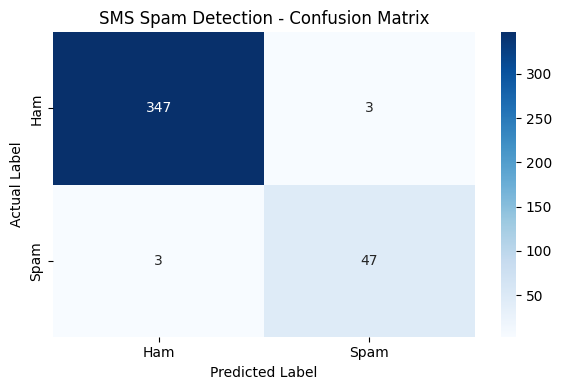

In [11]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SMS Spam Detection - Confusion Matrix")
plt.tight_layout()
plt.show()


In [12]:

def predict_sms(message):
    sequence = tokenizer.texts_to_sequences([message])
    padded = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    probability = float(
        model.predict(padded, verbose=0)[0][0]
    )

    prediction = "SPAM" if probability >= 0.5 else "HAM"

    print("Message:", message)
    print("Prediction:", prediction)
    print(f"Spam probability: {probability:.2%}")
    print("-" * 40)

# Test unseen messages
predict_sms("Congratulations! You have won a free prize. Call now!")
predict_sms("Hi, are we meeting at college tomorrow?")
predict_sms("URGENT! Claim your cash reward now!")
predict_sms("Please send me the class notes.")



Message: Congratulations! You have won a free prize. Call now!
Prediction: SPAM
Spam probability: 92.66%
----------------------------------------
Message: Hi, are we meeting at college tomorrow?
Prediction: HAM
Spam probability: 2.49%
----------------------------------------
Message: URGENT! Claim your cash reward now!
Prediction: SPAM
Spam probability: 92.59%
----------------------------------------
Message: Please send me the class notes.
Prediction: HAM
Spam probability: 10.14%
----------------------------------------


In [13]:

model.save("/content/sms_spam_lstm.keras")

print("SMS Spam Detection model saved successfully!")


SMS Spam Detection model saved successfully!
